# DP1 – Handling missing data by removal of data records

**Data:** `dataIsRemovalAllowed.csv` – 3 columns: `gender` (0/1), `age`, `preference` (score 0–10).
**Goal:** estimate the **mean preference** for the product.

**Question (a):** Can we simply delete the rows that have a missing preference?
**Expected answer:** **NO.** We will show *with plots* why.

### Key idea – types of missing data
| Type | Meaning | Is deleting rows OK? |
|---|---|---|
| **MCAR** (Missing Completely At Random) | missingness has nothing to do with the data | yes (we only lose some data) |
| **MAR / MNAR** (non-random) | missingness depends on other variables (e.g. age) or on the value itself | **no** – the rest of the data is no longer representative → **bias** |

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

## 1. Load the data
The file has no header, so we give the columns names ourselves.
`NaN` in the file means "missing value" – pandas reads it automatically as `NaN`.

In [2]:
df = pd.read_csv("../dataIsRemovalAllowed.csv", header=None, names=["gender", "age", "preference"])
print(df.head())
print("\nNumber of rows:", len(df))
print("Missing values per column:")
print(df.isna().sum())

   gender  age  preference
0       1   67         NaN
1       0   29      3.3435
2       1   14      2.9387
3       1   44         NaN
4       1   61         NaN

Number of rows: 1000
Missing values per column:
gender          0
age             0
preference    242
dtype: int64


➡ Only the column `preference` has missing values (242 of 1000 rows ≈ 24 %).

## 2. Who is missing? – missing rate by age
We create a helper column `missing` (True/False) and look at how often values are missing in each age group.

age_group
(0, 20]      0.000000
(20, 40]     0.000000
(40, 60]    51.984127
(60, 80]    45.491803
Name: missing, dtype: float64


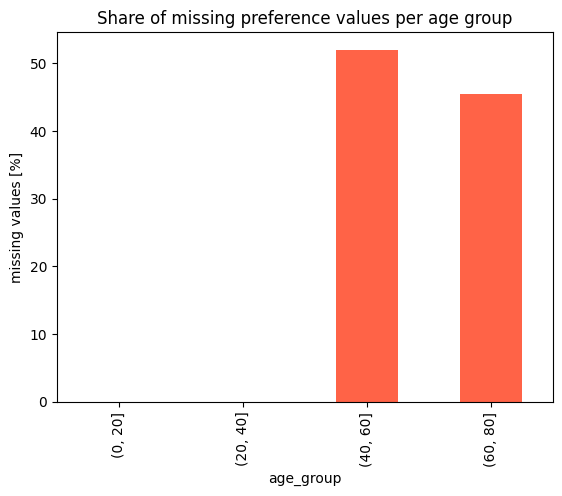

In [3]:
df["missing"] = df["preference"].isna()
df["age_group"] = pd.cut(df["age"], bins=[0, 20, 40, 60, 80])

missing_rate = df.groupby("age_group", observed=True)["missing"].mean() * 100
print(missing_rate)

missing_rate.plot(kind="bar", color="tomato")
plt.ylabel("missing values [%]")
plt.title("Share of missing preference values per age group")
plt.show()

➡ **People younger than 40 never have a missing value**, but about **50 % of people older than 40** are missing.
So the missingness is **not random** – it depends on age.

## 3. How does preference depend on age?
Scatter plot of the rows we *do* know.

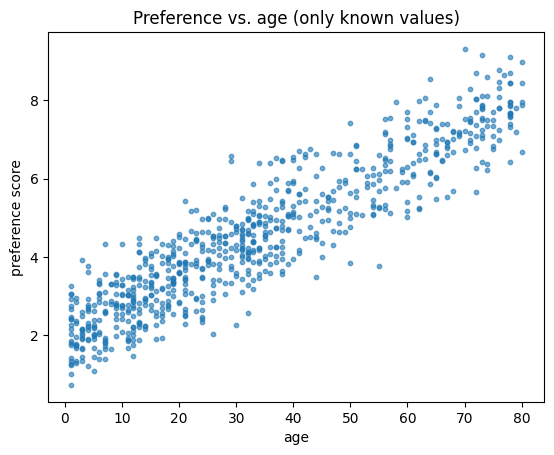

Correlation age <-> preference: 0.92


In [4]:
known = df.dropna()
plt.scatter(known["age"], known["preference"], s=10, alpha=0.6)
plt.xlabel("age")
plt.ylabel("preference score")
plt.title("Preference vs. age (only known values)")
plt.show()

print("Correlation age <-> preference:", round(known["age"].corr(known["preference"]), 2))

➡ There is a strong positive relation (correlation ≈ 0.92): **older people like the product more.**

## 4. Putting it together
- Older people → higher preference
- Older people → much more often missing

So when we delete the rows with missing values, we mainly delete **older people with high scores**.
The remaining data contains too many young people with low scores → the **mean is too low (underestimated)**.

The next plot shows the age distribution **before** and **after** deleting the rows.

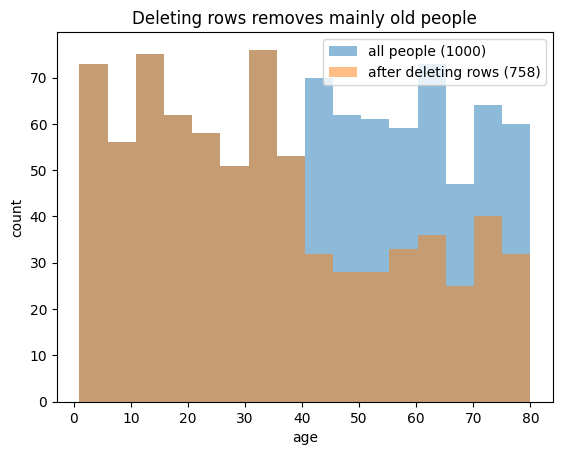

In [5]:
plt.hist(df["age"], bins=16, alpha=0.5, label="all people (1000)")
plt.hist(known["age"], bins=16, alpha=0.5, label="after deleting rows (758)")
plt.xlabel("age")
plt.ylabel("count")
plt.title("Deleting rows removes mainly old people")
plt.legend()
plt.show()

## 5. How big is the error?
We do not know the true missing values, but we can estimate them: in each age group we take the mean preference of the known people
(this works because inside one age group the missingness is roughly random).
Then we compare:
- **complete-case mean** = mean after deleting rows
- **age-corrected mean** = mean of the group means, weighted by how many people are in each group

Mean after deleting rows : 4.53
Age-corrected mean       : 4.99


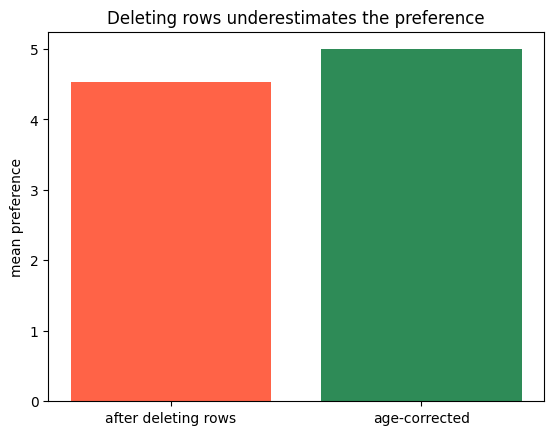

In [6]:
mean_after_deletion = known["preference"].mean()

group_mean = df.groupby("age_group", observed=True)["preference"].mean()   # mean of known values per group
group_size = df.groupby("age_group", observed=True).size()                  # ALL people per group
mean_corrected = (group_mean * group_size).sum() / group_size.sum()

print("Mean after deleting rows :", round(mean_after_deletion, 2))
print("Age-corrected mean       :", round(mean_corrected, 2))

plt.bar(["after deleting rows", "age-corrected"], [mean_after_deletion, mean_corrected], color=["tomato", "seagreen"])
plt.ylabel("mean preference")
plt.title("Deleting rows underestimates the preference")
plt.show()

## Conclusion (a)
**No, rows must not be removed here.**
- The missing values are **not random**: they appear only for people older than 40.
- Older people give **higher** preference scores.
- Deleting the rows therefore removes many high scores → the mean preference is **underestimated** (≈ 4.5 instead of ≈ 5.0).

**Rule:** deleting rows is only safe when data is *missing completely at random* (MCAR). Always check first *who* is missing!